In [1]:
import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)


In [2]:
df = pd.read_csv("../src/data/raw/churn_data.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

from src.data.preprocessor import transform_raw_data, get_preprocessor

data = df.copy()

data = transform_raw_data(data)
# data = pd.get_dummies(data, columns=["MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"], drop_first=True)
# data[data.select_dtypes(include='bool').columns] = data[data.select_dtypes(include='bool').columns].astype(int)
X = data.drop(columns="Churn")
y = data["Churn"]
X

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,0,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85
1,1,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50
2,1,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15
3,1,0,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75
4,0,0,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65
5,0,0,0,0,8,1,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,1,Electronic check,99.65,820.50
6,1,0,0,1,22,1,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,1,Credit card (automatic),89.10,1949.40
7,0,0,0,0,10,0,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,0,Mailed check,29.75,301.90
8,0,0,1,0,28,1,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,1,Electronic check,104.80,3046.05
9,1,0,0,1,62,1,No,DSL,Yes,Yes,No,No,No,No,One year,0,Bank transfer (automatic),56.15,3487.95


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
import xgboost as xgb

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

pipeline = Pipeline([
    ('prep', get_preprocessor()),
    ('clf', xgb.XGBClassifier(n_estimators=500, learning_rate=0.03, max_depth=6, scale_pos_weight=2.77, n_jobs=-1)),
])
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ohe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remain

In [6]:
from sklearn.metrics import classification_report, average_precision_score

y_pred_proba = pipeline.predict_proba(X_test)[:, 1]
CUSTOM_THRESHOLD = 0.30
y_pred_custom = (y_pred_proba >= CUSTOM_THRESHOLD).astype(int)
# y_pred = pipeline.predict(X_test)

print(f"PR-AUC: {average_precision_score(y_test, y_pred_proba)}\n")
print(classification_report(y_test, y_pred_custom))

PR-AUC: 0.6462499248090693

              precision    recall  f1-score   support

           0       0.93      0.65      0.76      1035
           1       0.47      0.86      0.61       374

    accuracy                           0.71      1409
   macro avg       0.70      0.76      0.69      1409
weighted avg       0.81      0.71      0.72      1409



NameError: name 'pr_auc' is not defined

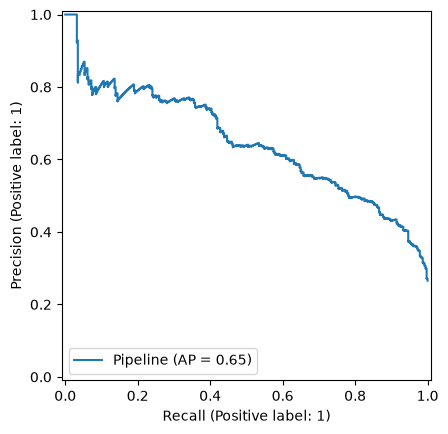

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_estimator(pipeline, X_test, y_test)
plt.show()

In [8]:
#hyperparameter tuning with optuna
import optuna
from sklearn.metrics import recall_score
from sklearn.pipeline import Pipeline

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 900),
        "max_depth": trial.suggest_int("max_depth", 1, 10),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 5),
        "reg_lambda": trial.suggest_float("reg_lambda", 0, 5),
        "random_state": 42,
        "n_jobs": -1,
        "scale_pos_weight": (y_train == 0).sum() / (y_train == 1).sum(),
        "eval_metric": "logloss",
    }

    model = Pipeline([
        ("prep", get_preprocessor()),
        ("clf", xgb.XGBClassifier())
    ])
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    y_pred = (proba >= CUSTOM_THRESHOLD).astype(int)
    return recall_score(y_test, y_pred, pos_label=1)


study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=20)

print(f"Best parameters: {study.best_params}")
print(f"Best recall: {study.best_value}")

/home/vladyslav/PycharmProjects/ChurnProj/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-10-29 13:40:06,728] A new study created in memory with name: no-name-aa933b4d-e50a-4084-8103-4021d316e20f
[I 2026-10-29 13:40:07,613] Trial 0 finished with value: 0.6898395721925134 and parameters: {'n_estimators': 603, 'max_depth': 3, 'min_child_weight': 8, 'subsample': 0.9620668877189917, 'colsample_bytree': 0.9520819712892232, 'gamma': 4.542215222182129, 'reg_alpha': 1.2921389676740374, 'reg_lambda': 4.635940920437386}. Best is trial 0 with value: 0.6898395721925134.
[I 2026-10-29 13:40:07,728] Trial 1 finished with value: 0.6898395721925134 and parameters: {'n_estimators': 501, 'max_depth': 7, 'min_child_weight': 3, 'subsample': 0.9150293313851949, 'colsample_bytree': 0.5747750916098621, 'gamma': 

Best parameters: {'n_estimators': 603, 'max_depth': 3, 'min_child_weight': 8, 'subsample': 0.9620668877189917, 'colsample_bytree': 0.9520819712892232, 'gamma': 4.542215222182129, 'reg_alpha': 1.2921389676740374, 'reg_lambda': 4.635940920437386}
Best recall: 0.6898395721925134


In [9]:
from sklearn.metrics import confusion_matrix

final_model = Pipeline([
    ('prep', get_preprocessor()),
    ('clf', xgb.XGBClassifier(**study.best_params))
])
final_model.fit(X_train, y_train)
y_pred_proba = final_model.predict_proba(X_test)[:, 1]
CUSTOM_THRESHOLD = 0.15
y_pred_custom = (y_pred_proba >= CUSTOM_THRESHOLD).astype(int)
# y_pred = pipeline.predict(X_test)

print(f"PR-AUC: {average_precision_score(y_test, y_pred_proba)}\n")
print(classification_report(y_test, y_pred_custom))
print(recall_score(y_test, y_pred_custom, pos_label=1))
print(confusion_matrix(y_test, y_pred_custom))

PR-AUC: 0.6601120005162445

              precision    recall  f1-score   support

           0       0.94      0.57      0.71      1035
           1       0.43      0.90      0.58       374

    accuracy                           0.66      1409
   macro avg       0.69      0.74      0.65      1409
weighted avg       0.81      0.66      0.68      1409

0.9010695187165776
[[589 446]
 [ 37 337]]


In [ ]:
from matplotlib import pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay
PrecisionRecallDisplay.from_estimator(final_model, X_test, y_test)
plt.show()